In [1]:
import torch
import importlib
import sys
import numpy as np
sys.path.append("/home/hkerino/Documents/next_oso")

from data_functions import dataset
from collate import pad_nextoso_collate
import utils_data


PATH_TO_DATA_s2 = "/home/hkerino/Documents/nextoso-dataset/data/10m/s2"
PATH_TO_DATA_label = "/home/hkerino/Documents/nextoso-dataset/data/10m/labels"
PATH_TO_OSO_CLASSES = "/home/hkerino/Documents/nextoso-dataset/data/auxiliary/OSO/oso_classes.csv"

batch_size = 4

In [2]:
dt = dataset.next_oso_Dataset(path_s2=PATH_TO_DATA_s2, path_label=PATH_TO_DATA_label, path_oso_class=PATH_TO_OSO_CLASSES,norm=True, folds=None, date_type='raw')
dl = torch.utils.data.DataLoader(dt, batch_size=batch_size, collate_fn=pad_nextoso_collate, shuffle=True)

(<Figure size 1500x800 with 10 Axes>, <Figure size 800x800 with 2 Axes>)

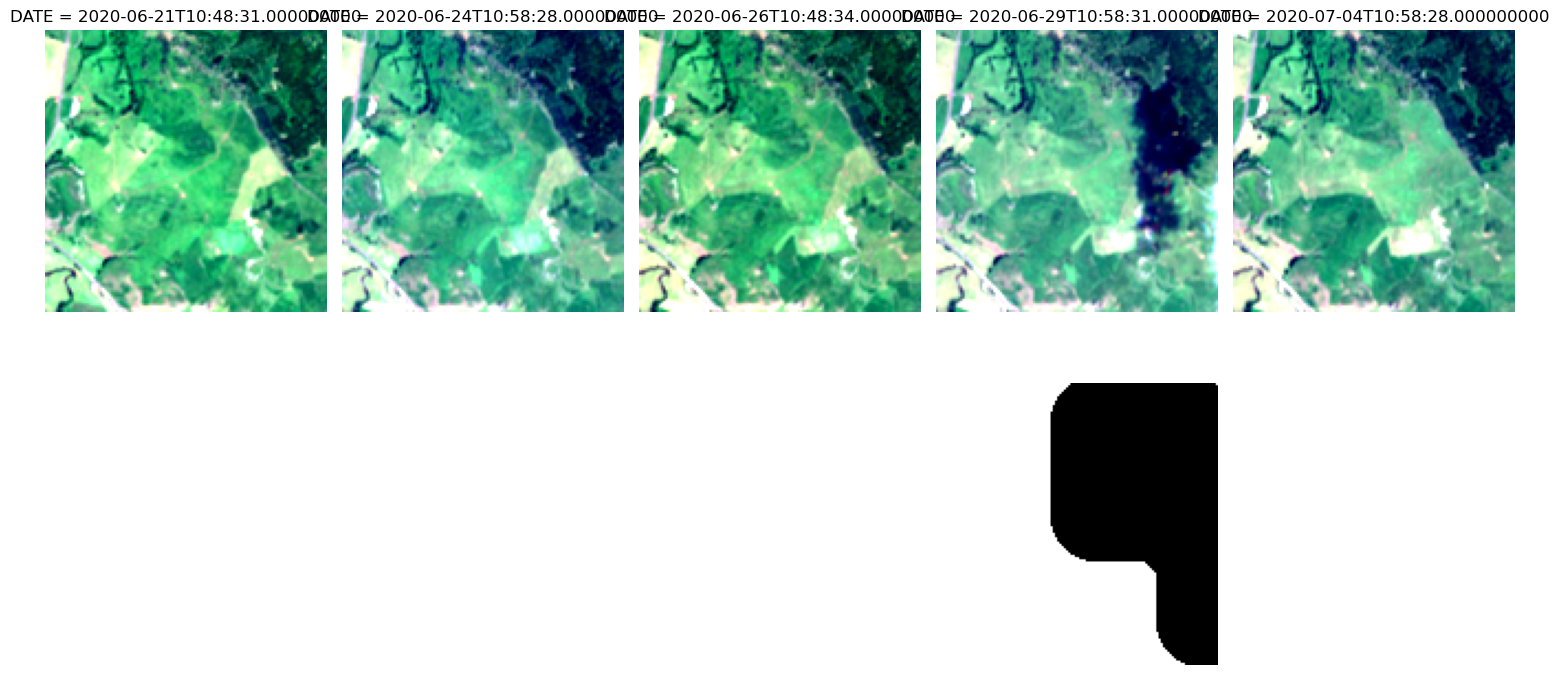

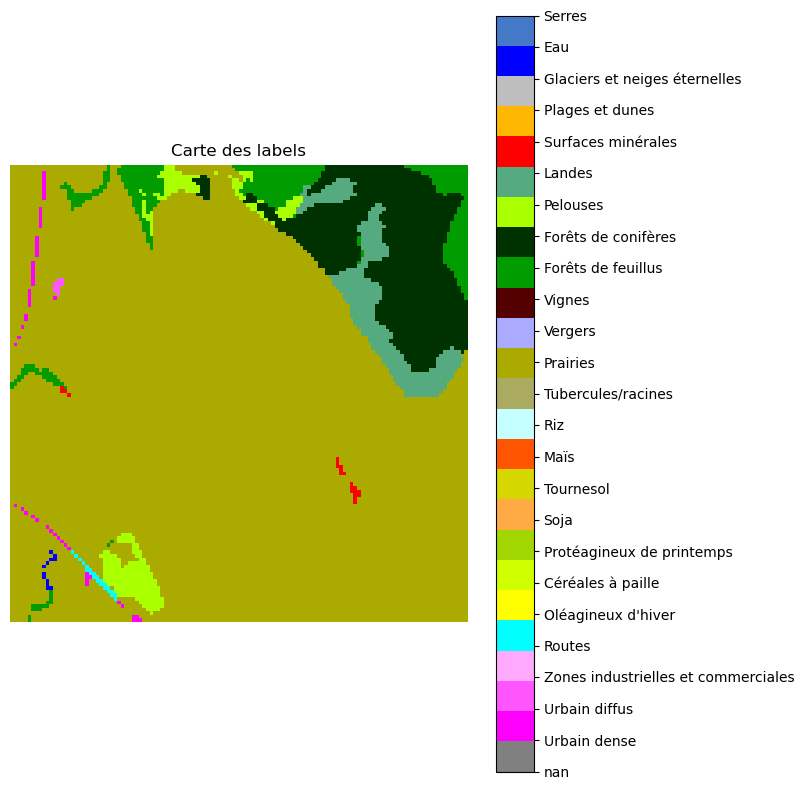

In [3]:
utils_data.plot_nextoso(dt, idx=100, first_date=20)

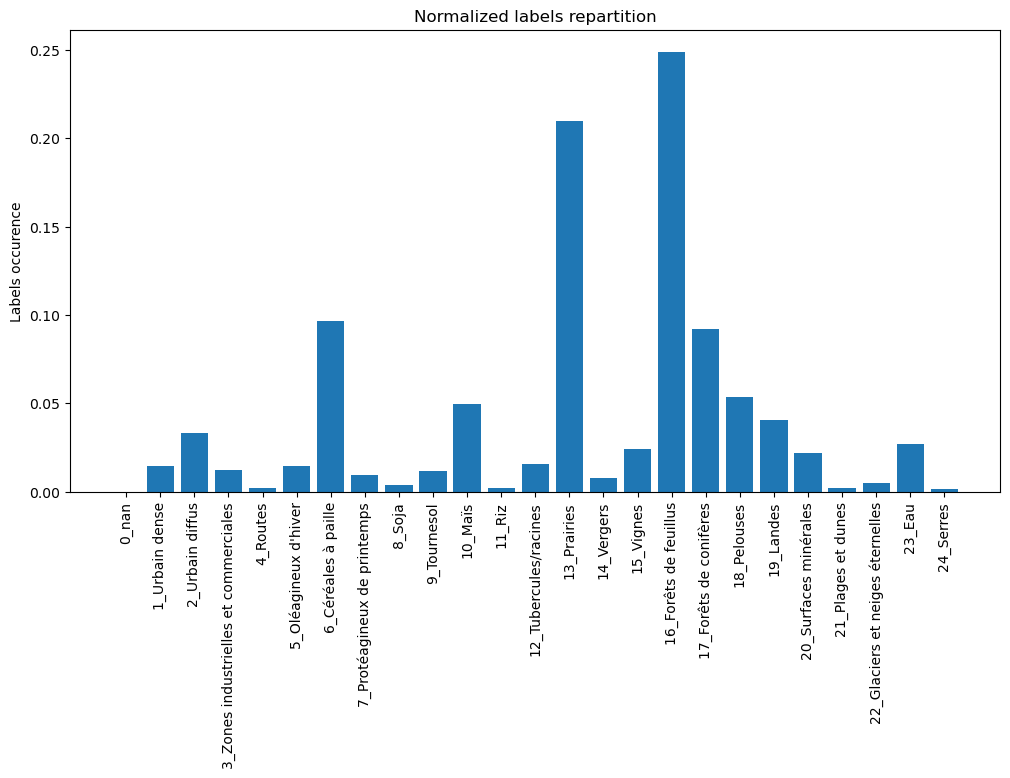

In [5]:
count = utils_data.count_label(dt)

In [6]:
np.max(count[1:]) / np.min(count[1:]) 

np.float64(138.47075713781493)

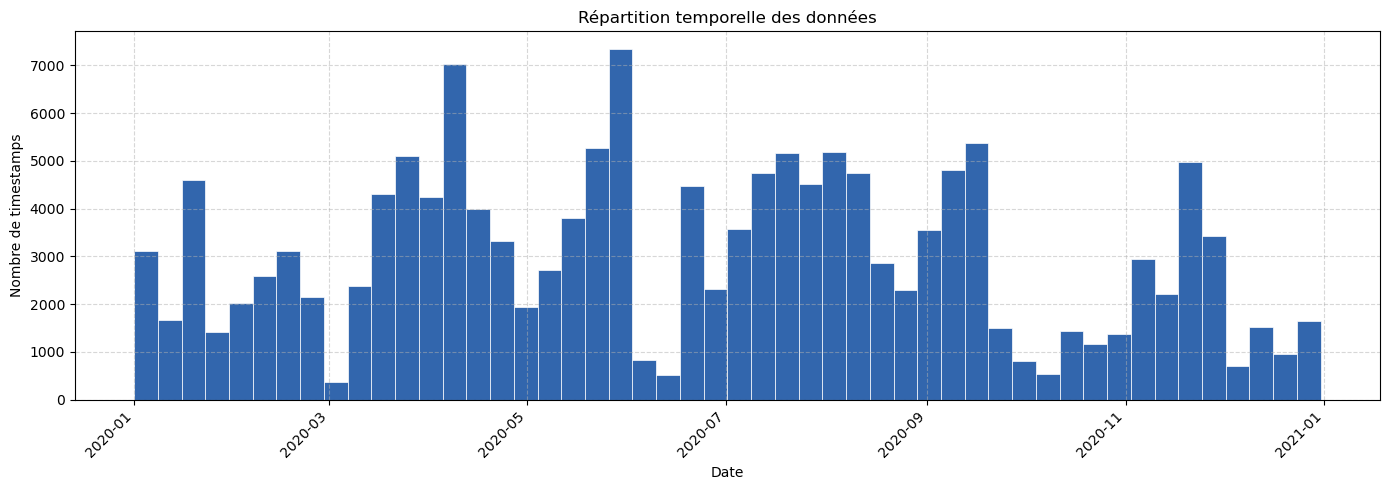

array(['2020-01-01', '2020-01-06', '2020-01-11', ..., '2020-12-25',
       '2020-12-28', '2020-12-30'], shape=(152632,), dtype='datetime64[D]')

In [ ]:
importlib.reload(utils_data)
dates = utils_data.count_timestep_dataloard(dt) 

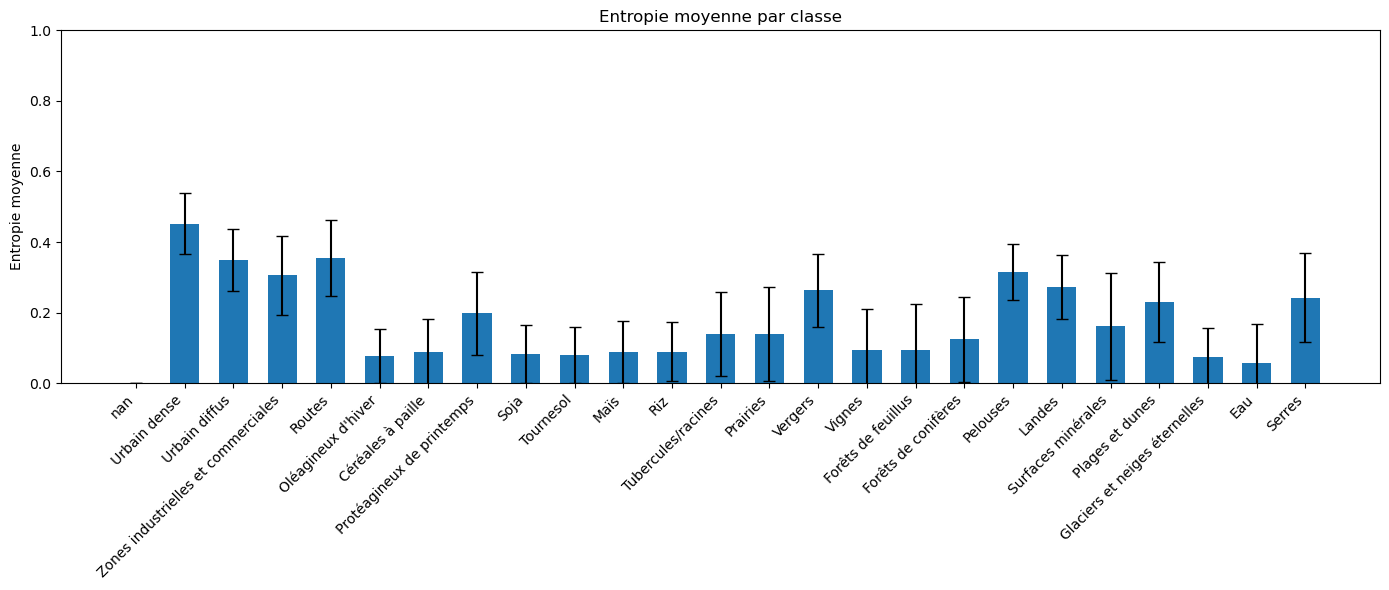

In [ ]:
entropy_per_class = utils_data.mean_entropy_per_class(
    PATH_TO_DATA_label, PATH_TO_OSO_CLASSES
)

In [ ]:
mean_entropy = utils_data.mean_entropy_per_class_per_eco_zone(PATH_TO_DATA_label, PATH_TO_OSO_CLASSES)

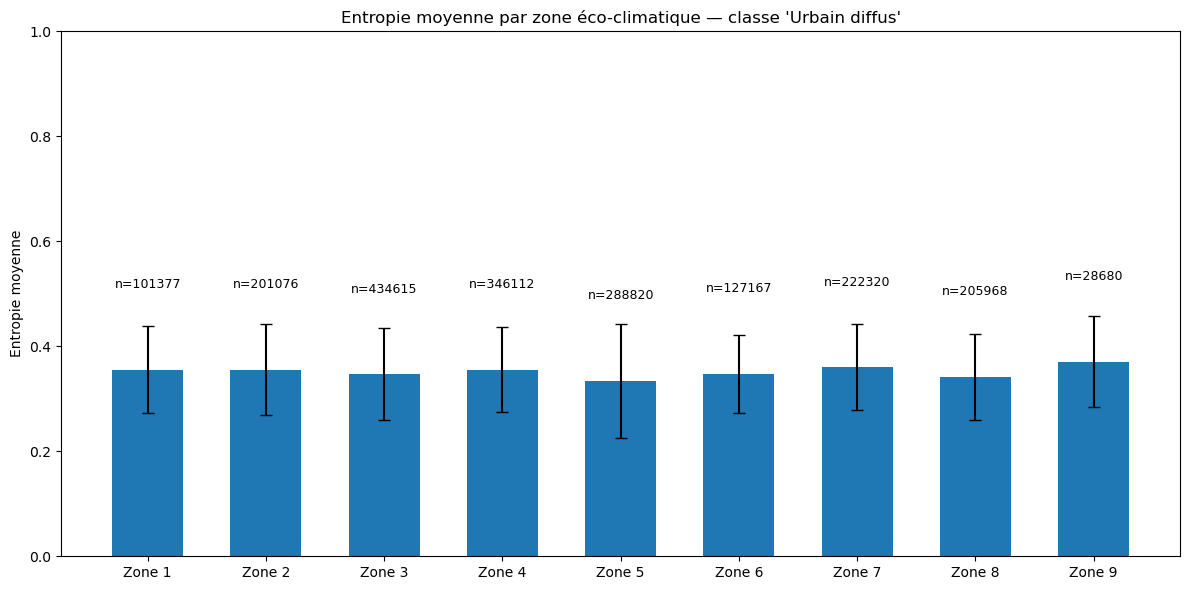

In [116]:
utils_data.plot_entropy_per_zone_for_class(mean_entropy=mean_entropy, classe=2)

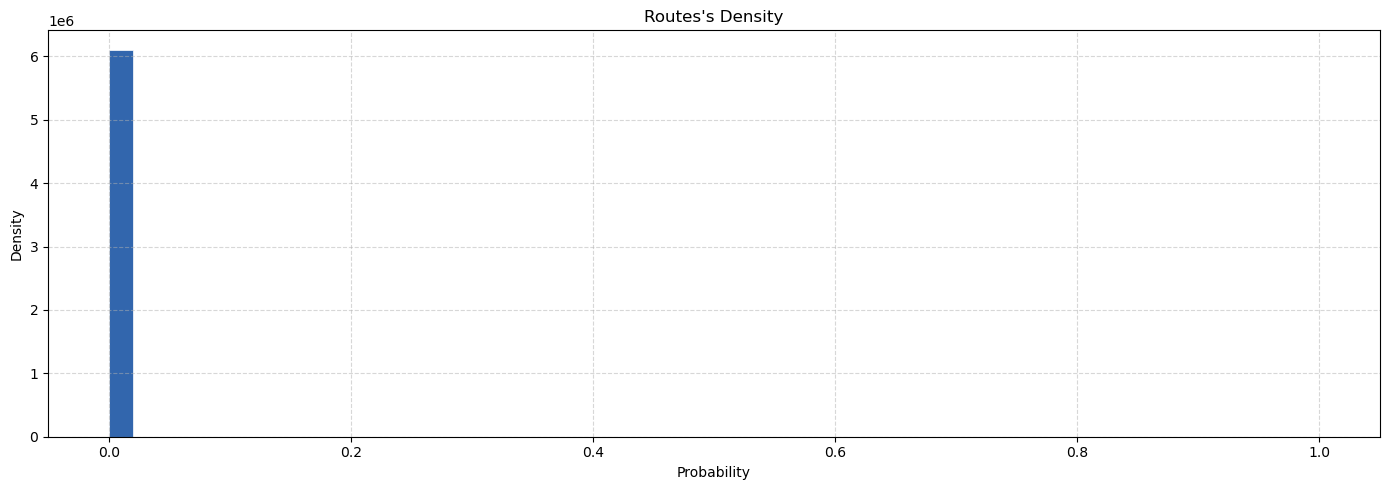

In [70]:
importlib.reload(utils_data)
density_class = utils_data.density_repartion(PATH_TO_DATA_label, 'Routes')

In [69]:
density_class

array([0.0002665 , 0.00106599, 0.00053299, ..., 0.0014372 , 0.14173229,
       0.03508772], shape=(6105903,), dtype=float32)

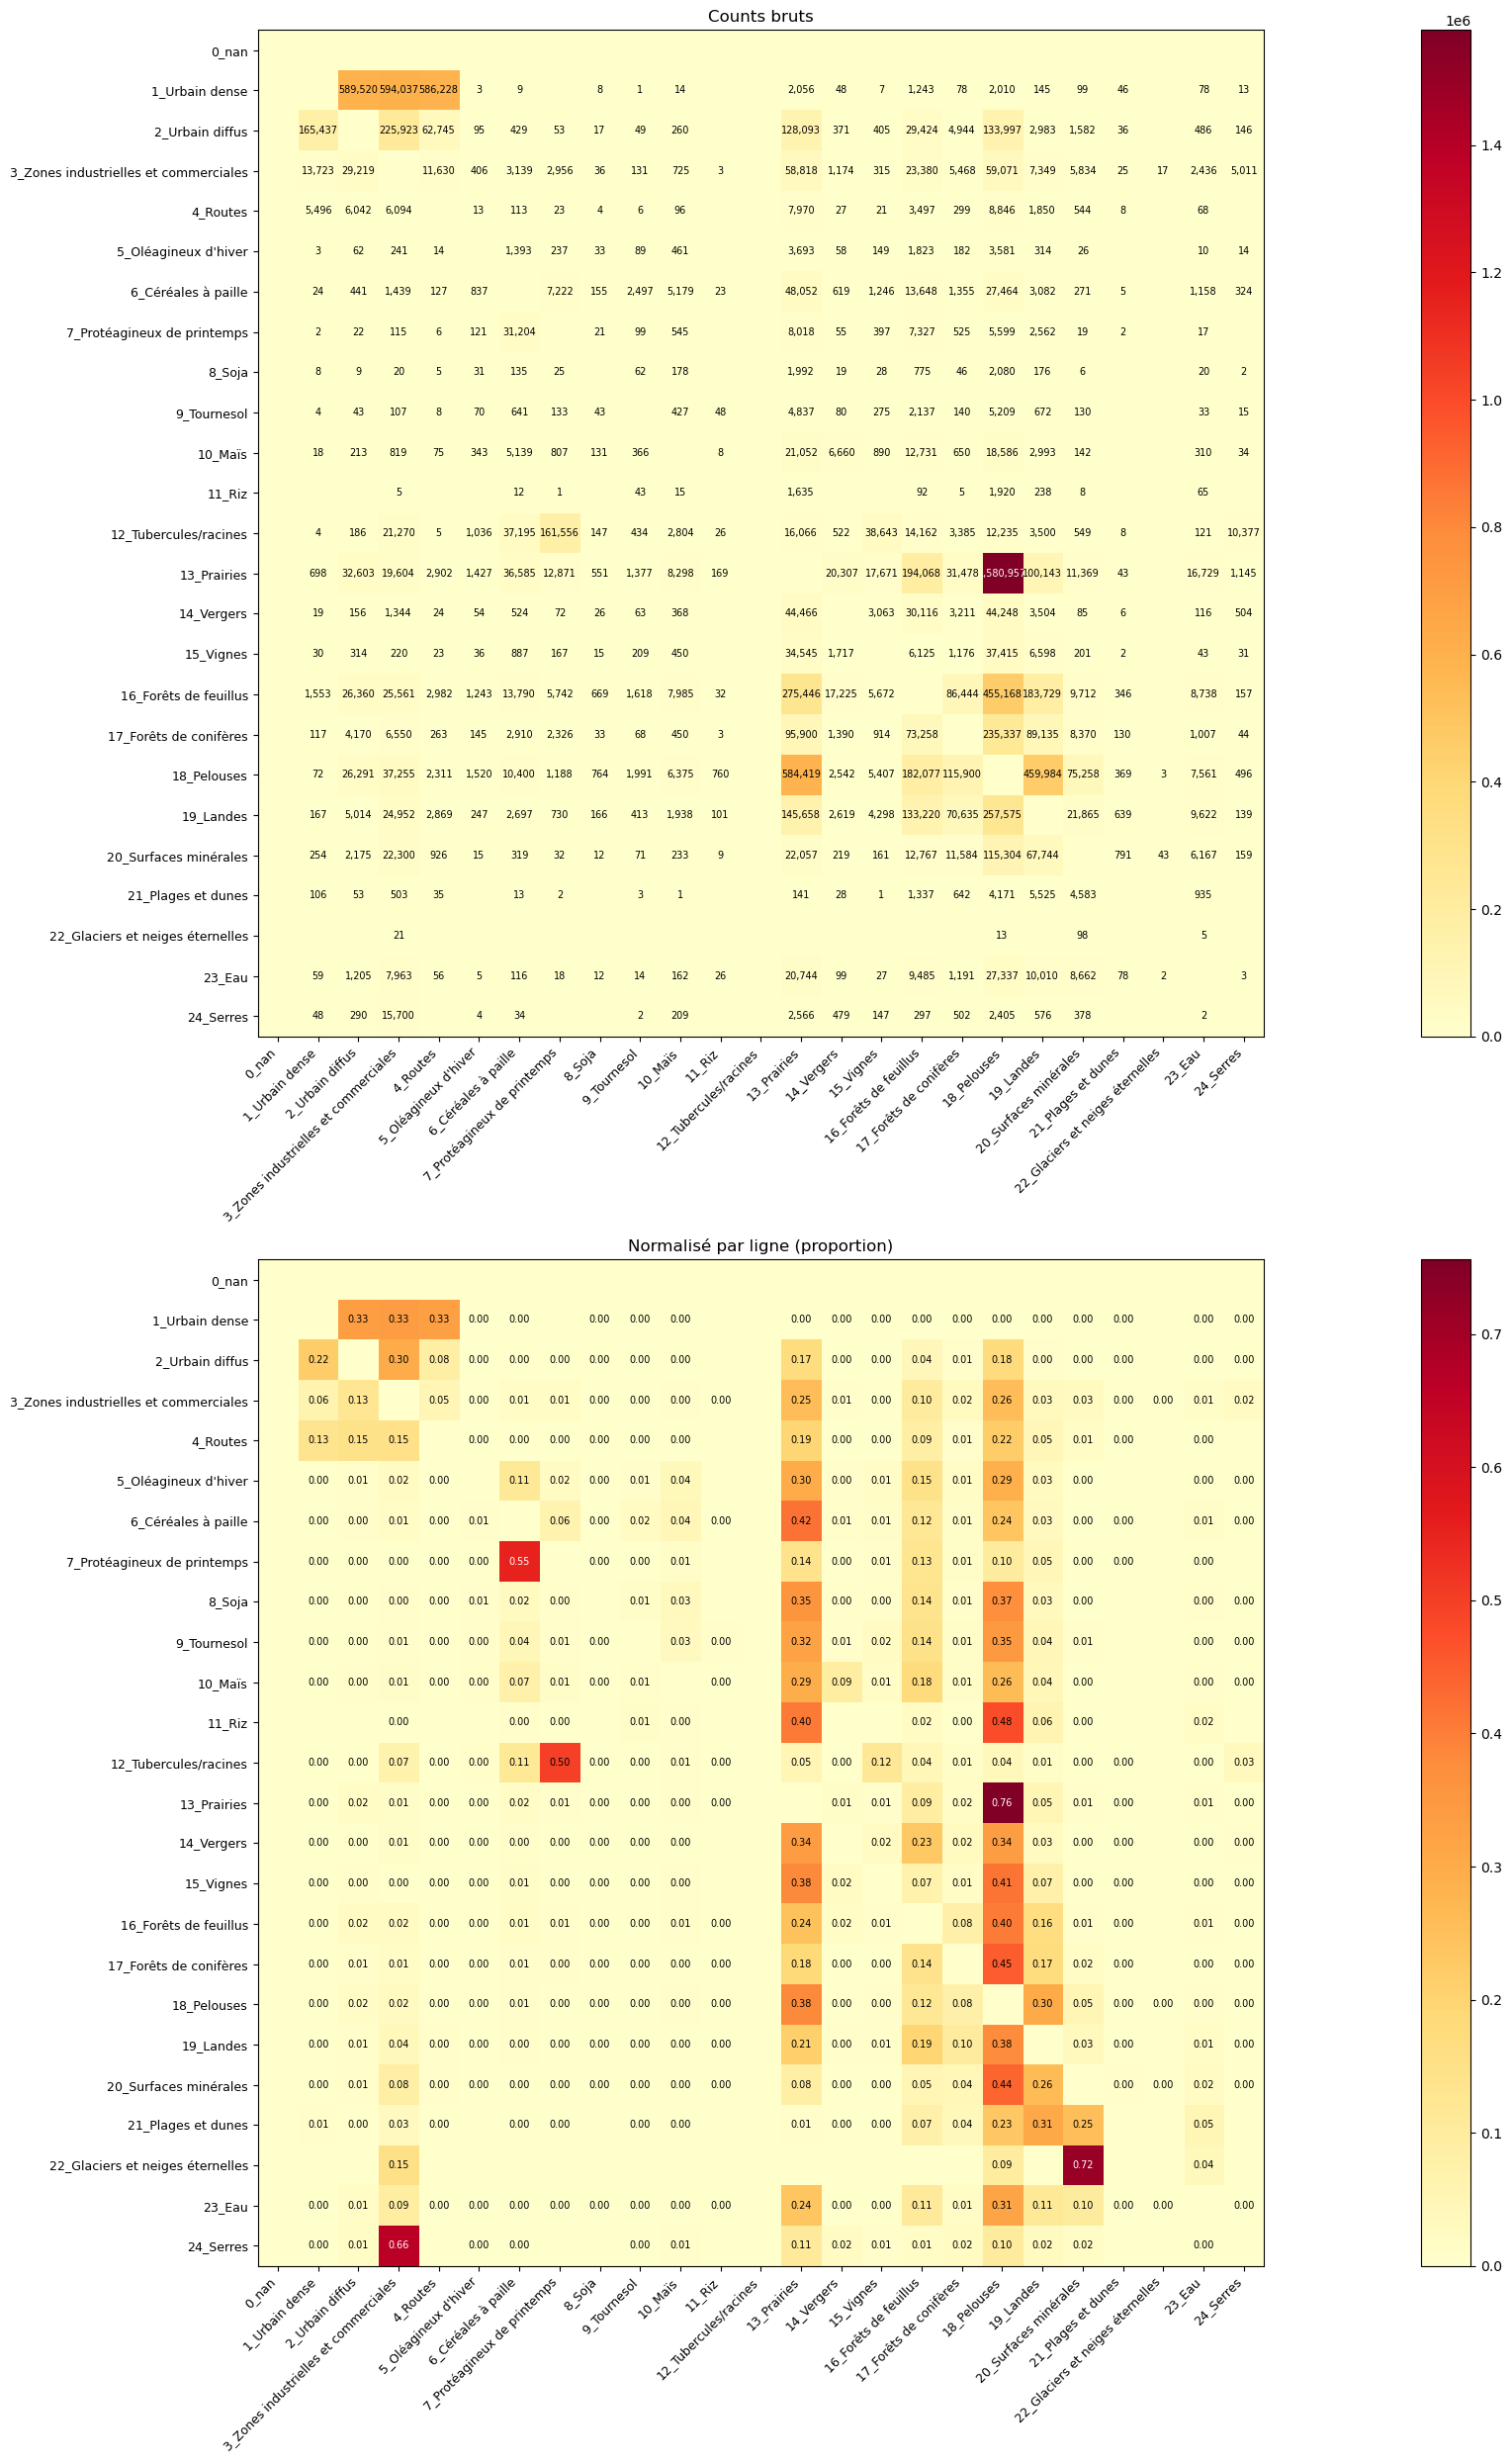

array([[      0,       0,       0,       0,       0,       0,       0,
              0,       0,       0,       0,       0,       0,       0,
              0,       0,       0,       0,       0,       0,       0,
              0,       0,       0,       0],
       [      0,       0,  589520,  594037,  586228,       3,       9,
              0,       8,       1,      14,       0,       0,    2056,
             48,       7,    1243,      78,    2010,     145,      99,
             46,       0,      78,      13],
       [      0,  165437,       0,  225923,   62745,      95,     429,
             53,      17,      49,     260,       0,       0,  128093,
            371,     405,   29424,    4944,  133997,    2983,    1582,
             36,       0,     486,     146],
       [      0,   13723,   29219,       0,   11630,     406,    3139,
           2956,      36,     131,     725,       3,       0,   58818,
           1174,     315,   23380,    5468,   59071,    7349,    5834,
             

In [117]:
importlib.reload(utils_data)
utils_data.plot_label_confusion(
    PATH_TO_DATA_label,
    PATH_TO_OSO_CLASSES,
    proba_threshold=0.5,
    secondary_threshold=0.2,
)